In [9]:

# step 1 instal libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping



In [2]:
# 1. Reproducibility
np.random.seed(42)
tf.random.set_seed(42)


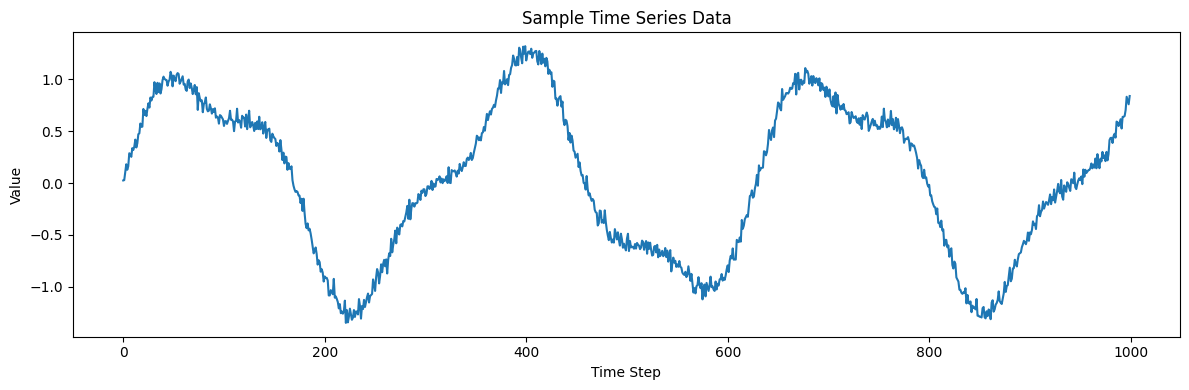

In [3]:

# 2. Create sample time-series data (no external dataset needed)
t = np.arange(1000)
data = np.sin(0.02 * t) + 0.3 * np.sin(0.05 * t)
data += np.random.normal(0, 0.05, len(t))
data = data.reshape(-1, 1)

plt.figure(figsize=(12, 4))
plt.plot(data)
plt.title("Sample Time Series Data")
plt.xlabel("Time Step")
plt.ylabel("Value")
plt.tight_layout()
plt.show()



In [4]:
# 3. Chronological train/test split
split = int(len(data) * 0.8)
train_data = data[:split]
test_data = data[split:]

# Fit scaler on training data only (avoids data leakage)
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)

# Add previous training values as context for the first test window
window_size = 30
test_input = np.concatenate([train_data[-window_size:], test_data], axis=0)
test_scaled = scaler.transform(test_input)

# 4. Convert series to sequences
def create_sequences(dataset, window=30):
    X, y = [], []
    for i in range(window, len(dataset)):
        X.append(dataset[i-window:i, 0])
        y.append(dataset[i, 0])
    X = np.array(X, dtype=np.float32).reshape(-1, window, 1)
    y = np.array(y, dtype=np.float32)
    return X, y

X_train, y_train = create_sequences(train_scaled, window_size)
X_test, y_test = create_sequences(test_scaled, window_size)

print("X_train shape:", X_train.shape)  # (samples, 30, 1)
print("X_test shape: ", X_test.shape)
print("Shape meaning: (samples, time steps, features)")



X_train shape: (770, 30, 1)
X_test shape:  (200, 30, 1)
Shape meaning: (samples, time steps, features)


In [5]:
# 5. Model builder: only recurrent layer changes
def build_model(model_type):
    if model_type == "SimpleRNN":
        recurrent_layer = SimpleRNN(32, input_shape=(window_size, 1))
    elif model_type == "GRU":
        recurrent_layer = GRU(32, input_shape=(window_size, 1))
    elif model_type == "LSTM":
        recurrent_layer = LSTM(32, input_shape=(window_size, 1))
    else:
        raise ValueError("Unknown model type: " + model_type)

    model = Sequential([recurrent_layer, Dense(1)])
    model.compile(optimizer="adam", loss="mse")
    return model

# 6. Train and evaluate each model on the same data
model_types = ["SimpleRNN", "GRU", "LSTM"]
results, histories, trained_models = {}, {}, {}

for model_type in model_types:
    print("\\n" + "=" * 45)
    print("Training:", model_type)
    print("=" * 45)

    model = build_model(model_type)
    model.summary()

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        shuffle=False,
        callbacks=[early_stop],
        verbose=1
    )

    pred_scaled = model.predict(X_test, verbose=0)
    predictions = scaler.inverse_transform(pred_scaled)
    actual = scaler.inverse_transform(y_test.reshape(-1, 1))

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))

    results[model_type] = {
        "MAE": mae,
        "RMSE": rmse,
        "predictions": predictions
    }
    histories[model_type] = history
    trained_models[model_type] = model

    print(f"{model_type} MAE:  {mae:.4f}")
    print(f"{model_type} RMSE: {rmse:.4f}")



\n=============================================
Training: SimpleRNN


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

...

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.0866 - val_loss: 0.0207
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0116 - val_loss: 0.0098
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0057 - val_loss: 0.0020
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0039 - val_loss: 0.0021
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0032 - val_loss: 0.0018
Epoch 6/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0029 - val_loss: 0.0016
Epoch 7/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0028 - val_loss: 0.0016
Epoch 8/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0026 - val_loss: 0.0015
Epoch 9/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0025 - val_loss: 0.0014
Epoch 10/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0024 - val_loss: 0.0013
Epoch 11/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0022 - val_loss: 0.0013
Epoch 12/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0

LSTM MAE:  0.0857
LSTM RMSE: 0.1000


\nFINAL COMPARISON
------------------------------------------
Model                MAE        RMSE
------------------------------------------
SimpleRNN         0.0586      0.0728
GRU               0.0566      0.0692
LSTM              0.0857      0.1000
------------------------------------------
Lowest RMSE on this test split: GRU
Lower MAE/RMSE is better; results depend on the dataset.


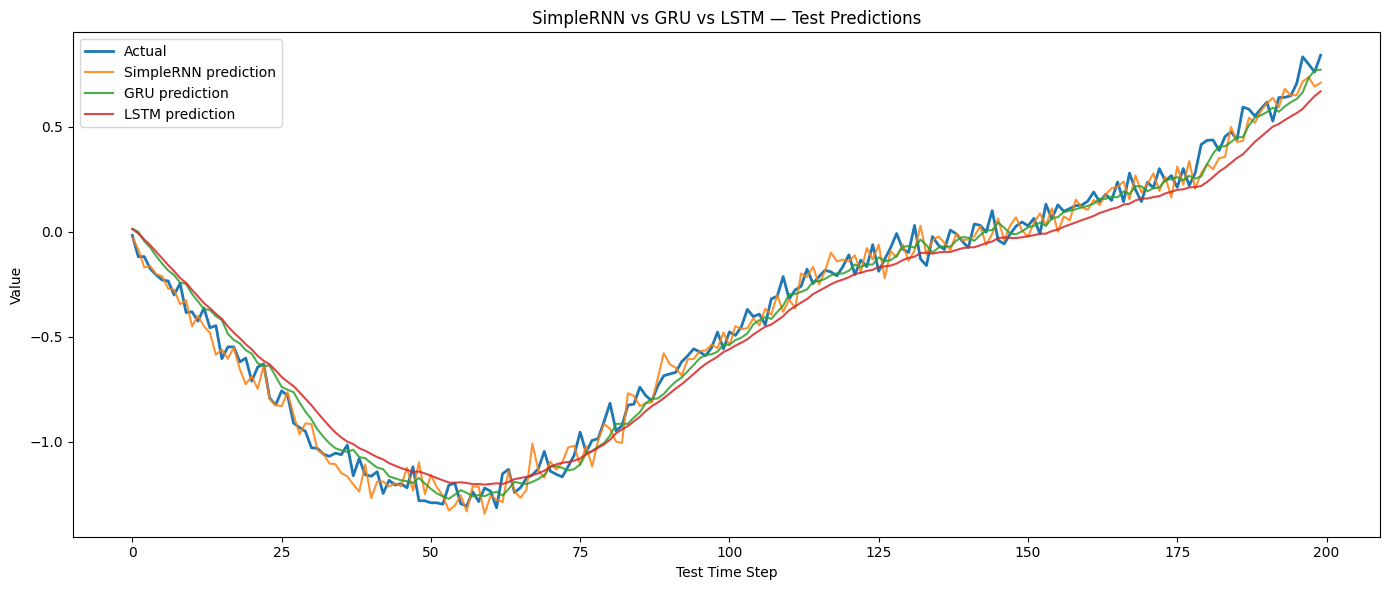

In [6]:
# 7. Print final comparison
print("\\nFINAL COMPARISON")
print("-" * 42)
print(f"{'Model':<12}{'MAE':>12}{'RMSE':>12}")
print("-" * 42)

for model_type in model_types:
    print(
        f"{model_type:<12}"
        f"{results[model_type]['MAE']:>12.4f}"
        f"{results[model_type]['RMSE']:>12.4f}"
    )

best_model = min(model_types, key=lambda name: results[name]["RMSE"])
print("-" * 42)
print("Lowest RMSE on this test split:", best_model)
print("Lower MAE/RMSE is better; results depend on the dataset.")

# 8. Plot actual vs model predictions
actual = scaler.inverse_transform(y_test.reshape(-1, 1))
plt.figure(figsize=(14, 6))
plt.plot(actual, label="Actual", linewidth=2)

for model_type in model_types:
    plt.plot(
        results[model_type]["predictions"],
        label=model_type + " prediction",
        alpha=0.85
    )

plt.title("SimpleRNN vs GRU vs LSTM — Test Predictions")
plt.xlabel("Test Time Step")
plt.ylabel("Value")
plt.legend()
plt.tight_layout()
plt.show()



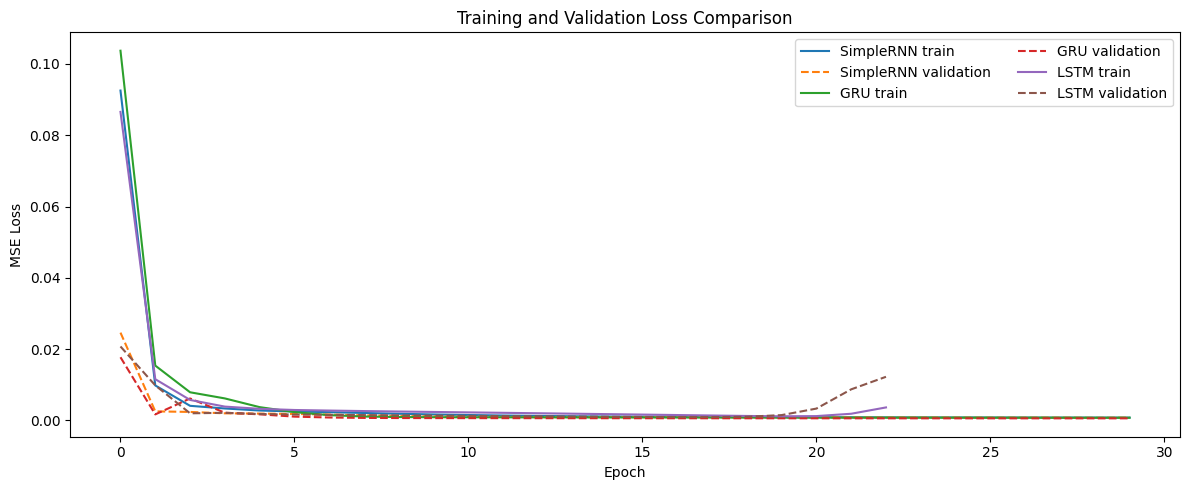

In [7]:
# 9. Compare training and validation losses
plt.figure(figsize=(12, 5))
for model_type in model_types:
    history = histories[model_type]
    plt.plot(history.history["loss"], label=model_type + " train")
    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=model_type + " validation"
    )

plt.title("Training and Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()



In [8]:
# 10. Quick concept recap
print("\\nCONCEPT SUMMARY")
print("SimpleRNN: simplest recurrent layer; can struggle with long-term dependencies.")
print("GRU: update + reset gates; often fewer parameters than LSTM.")
print("LSTM: input + forget + output gates and a separate cell state.")
print("MAE/RMSE measure prediction errors; lower is better.")


\nCONCEPT SUMMARY
SimpleRNN: simplest recurrent layer; can struggle with long-term dependencies.
GRU: update + reset gates; often fewer parameters than LSTM.
LSTM: input + forget + output gates and a separate cell state.
MAE/RMSE measure prediction errors; lower is better.
